# SI Fig. S6: likelihood surfaces and least-squares fits for Expt 3

S6a  the change in negative log-likelihood against mu under the spontaneous-only
       model, for each population.
  S6b  the same under the combined model, profiled over the other parameter, against
       mu and against mu_ind.  The unexposed control's mu_ind profile is flat towards
       zero; both UV populations have a clear optimum away from it.
  S6c  the spontaneous-only fit by least squares rather than maximum likelihood.
  S6d  the combined fit likewise.
  S6e  best-fit mu against bin count, for both estimators.
  S6f  best-fit mu_ind against bin count.  The two estimators agree at moderate bin
       counts and diverge as k grows, which is why every other panel uses k = 4000.

The dashed line on the likelihood panels marks the Wilks 95% threshold of 1.92, shown
as a guide to the curvature of the likelihood.  Reported confidence intervals are
percentile bootstrap rather than Wilks, because measurement noise breaks the
asymptotic assumption the threshold relies on.

Requires `20260907_expt3_fits.py`.  Runtime: ~2 min.

## The likelihood and loss surfaces

The same definitions the fit pipeline sweeps over every bin count; here they are evaluated at the one bin count these panels show. `barfly.expt3` holds identical versions for the batch fit.

In [1]:
def log_likelihood_surface(block, alpha):
    """Log-likelihood over the (mu, mu_ind) grid for one population, at fixed alpha.

    The mutant numbers are discretised onto coarse bins, and each grid point's model
    probability for those bins is read off the precomputed fine histogram.  Summing
    the log of the bin probability over lineages gives SI Eq. 12.
    """
    observed = alpha * block["mutants_at_alpha1"]
    edges = expt3.likelihood_bin_edges(observed)
    bin_of_lineage = np.clip(np.digitize(observed, edges) - 1, 0, len(edges) - 2)

    surface = np.zeros((len(expt3.MU_GRID), len(expt3.MU_IND_GRID)))
    for i_mu in range(len(expt3.MU_GRID)):
        for i_mu_ind in range(len(expt3.MU_IND_GRID)):
            pmf = expt3.rebin_histogram(block["fine_pmf"][i_mu, i_mu_ind],
                                        expt3.FINE_EDGES, edges)
            pmf = np.clip(pmf, expt3.MIN_PROBABILITY, None)
            pmf /= pmf.sum()
            surface[i_mu, i_mu_ind] = np.log(pmf)[bin_of_lineage].sum()
    return surface


def ccdf_loss_surface(block, alpha):
    """Least-squares loss over the (mu, mu_ind) grid for one population.

    Squared error between the log10 CCDF of the data and of the theory, the theory
    again read off the precomputed histogram.  Points where the simulated CCDF is
    below the Monte-Carlo noise floor are not scored.
    """
    observed = expt3.ccdf_of_samples(alpha * block["mutants_at_alpha1"],
                                     block["thresholds"])
    surface = np.full((len(expt3.MU_GRID), len(expt3.MU_IND_GRID)), np.inf)
    for i_mu in range(len(expt3.MU_GRID)):
        for i_mu_ind in range(len(expt3.MU_IND_GRID)):
            theory = expt3.ccdf_of_histogram(block["fine_pmf"][i_mu, i_mu_ind],
                                             expt3.FINE_EDGES, block["thresholds"])
            surface[i_mu, i_mu_ind] = expt3.ccdf_squared_error(observed, theory)
    return surface

alpha (fixed, from the control) = 3.4248; k values = [np.int64(1000), np.int64(2000), np.int64(4000), np.int64(6000), np.int64(8000), np.int64(12000), np.int64(16000), np.int64(25000), np.int64(32000)]


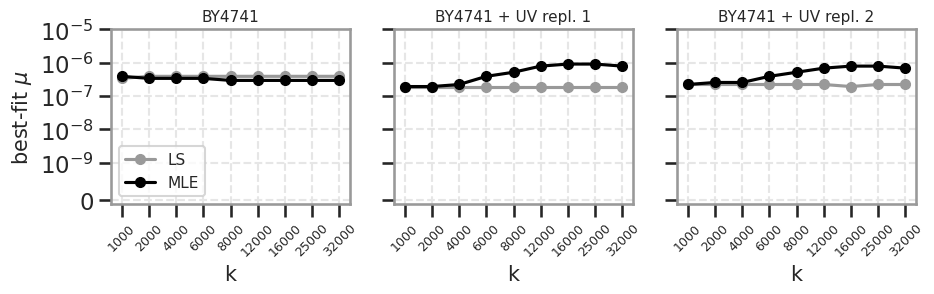

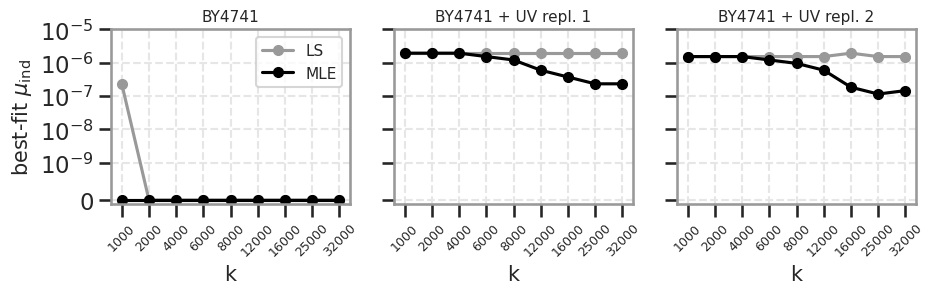

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from barfly import expt3, ld                                        # noqa: E402
from barfly.plotting import colorTable, use_paper_style               # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
CACHE = ROOT / "cache"
use_paper_style()

K_PLOT = 4000
WILKS_95 = 1.92
SEED = 20260907
np.random.seed(SEED)
t_start = time.time()

with open(CACHE / "expt3_precompute.pkl", "rb") as f:
    blocks = pickle.load(f)["blocks"]
ls_tbl = pd.read_csv(CACHE / "expt3_ls_summary.csv")
mle_tbl = pd.read_csv(CACHE / "expt3_mle_summary.csv")
kvals = sorted(ls_tbl["k"].unique())
alpha = float(ls_tbl["alpha"].iloc[0])
print(f"alpha (fixed, from the control) = {alpha:.4f}; k values = {kvals}")

# --- S6e, S6f: best fit against k -------------------------------------------
xpos = np.arange(len(kvals))
for fname, col, lab in (("figS06e_bestFitMu_vs_k.svg", "mu_best", r"best-fit $\mu$"),
                        ("figS06f_bestFitMuInd_vs_k.svg", "mu_ind_best",
                         r"best-fit $\mu_{\mathrm{ind}}$")):
    fig, axs = plt.subplots(1, 3, figsize=(3 / 4 * 0.8 * 16, 0.8 * 4), sharey=True)
    for ax, key in zip(axs, expt3.KEYS):
        for tbl, colour, label in ((ls_tbl, '0.6', "LS"),
                                   (mle_tbl, colorTable['k'], "MLE")):
            rows = tbl.loc[tbl.key == key].set_index("k").loc[kvals]
            ax.plot(xpos, rows[col].values, "-o", color=colour, markersize=7, label=label)
        ax.set_xticks(xpos)
        ax.set_xticklabels([str(k) for k in kvals], rotation=45, fontsize=9)
        ax.set_xlabel("k")
        ax.set_title(expt3.KEY_LABELS[key], fontsize=11)
    axs[0].set_yscale("symlog", linthresh=1e-9)
    axs[0].set_ylim(-1e-10, 1e-5)
    axs[0].set_ylabel(lab)
    axs[0].legend(fontsize=11)
    plt.tight_layout(); plt.savefig(OUT / fname, bbox_inches="tight", dpi=300); plt.show()

# --- rebuild the likelihood and loss surfaces at k = 4000 -------------------
log_likelihood_by_key, loss_by_key = {}, {}

## The CCDF overlay

Data against best-fit theory, one panel per population. Used twice below: once for the spontaneous-only model and once for the combined one.

In [3]:
def plot_ccdf_overlay(library, fits, n_bins, path, model, n_replicates=10_000_000):
    """Mutant-number CCDF with the best-fit theory, one panel per population.

    `model` selects which fit to draw: "spontaneous" takes the mu_ind = 0 slice,
    "combined" the full (mu, mu_ind) optimum.  `fits` is either estimator's summary
    table, so the same call renders the maximum-likelihood and the least-squares
    version of the panel.

    Data are the observed mutant numbers per virtual lineage, scaled by the fitted
    alpha.  Theory is a fresh simulation at the best-fit rates: the spontaneous part
    from the Luria-Delbruck process, plus -- for the combined model -- an independent
    Poisson(mu_ind * N) draw per replicate, which is what induced mutations
    contribute.
    """
    theory_x = np.logspace(0, 4, 100)

    figure, axes = plt.subplots(1, len(expt3.KEYS), figsize=(0.8 * 16, 0.8 * 4),
                                sharey=True, sharex=True)
    for axis, key in zip(axes, expt3.KEYS):
        row = fits.loc[(fits.key == key) & (fits.k == n_bins)].iloc[0]
        block = library[(key, n_bins)]
        colour = colorTable["o"] if "UV" in key else colorTable["k"]

        mu = row["mu_best_muind0"] if model == "spontaneous" else row["mu_best"]
        simulated = ld.simulate_ld(float(mu), 1.0, n_replicates,
                                   block["population_per_bin"])
        if model == "combined" and row["mu_ind_best"] > 0:
            simulated = simulated + np.random.poisson(
                float(row["mu_ind_best"]) * block["population_per_bin"], n_replicates)
        simulated.sort()
        theory_y = ld.ccdf_of_sorted(simulated, theory_x)
        del simulated

        observed = np.sort(row["alpha"] * block["mutants_at_alpha1"])
        # log-spaced up to the fifteenth largest, then each jackpot individually
        plot_x = np.concatenate([np.logspace(0, np.log10(observed[-15]), 40),
                                 observed[-15:]])
        axis.plot(plot_x, ld.ccdf_of_sorted(observed, plot_x), ".",
                  markersize=25, color=colour, rasterized=True, alpha=0.3)
        axis.plot(theory_x, theory_y, "-", color=colour, linewidth=3.5)

        annotation = (f"$\\mu$ = {mu:.1e}" if model == "spontaneous" else
                      f"$\\mu$ = {mu:.1e}\n"
                      f"$\\mu_{{\\mathrm{{ind}}}}$ = {row['mu_ind_best']:.1e}")
        axis.text(0.95, 0.95, annotation, transform=axis.transAxes,
                  verticalalignment="top", horizontalalignment="right")
        axis.set_xscale("log")
        axis.set_yscale("log")

    axes[0].set_xlim(8e-1, 1e4)
    axes[0].set_ylim(1e-4, 2)
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()

In [4]:
def dnll_panel(values, xgrid, fname, xlabel, symlog_x=False):
    fig, axs = plt.subplots(1, 3, figsize=(0.8 * 16, 0.8 * 4), sharey=True)
    for ax, key in zip(axs, expt3.KEYS):
        neg_log_likelihood = values(key)
        ax.plot(xgrid, neg_log_likelihood - np.min(neg_log_likelihood), "-o", color=colorTable['k'],
                markersize=4, linewidth=1.2)
        ax.axhline(WILKS_95, color='gray', linestyle='--', linewidth=1.5)
        if symlog_x:
            ax.set_xscale("symlog", linthresh=1e-10)
            ax.set_xlim(left=0)
            ax.set_xticks([0, 1e-9, 1e-7, 1e-5])
            ax.set_xticklabels(['0', r'$10^{-9}$', r'$10^{-7}$', r'$10^{-5}$'], fontsize=11)
        else:
            ax.set_xscale("log")
        ax.set_xlabel(xlabel)
        ax.set_title(expt3.KEY_LABELS[key], fontsize=11)
    axs[0].set_yscale("symlog", linthresh=0.1)
    axs[0].set_ylim(bottom=0)
    axs[0].set_ylabel(r"$\Delta$ neg. log likelihood")
    plt.tight_layout(); plt.savefig(OUT / fname, bbox_inches="tight", dpi=300); plt.show()

In [5]:
sys.path.insert(0, str(ROOT))
from barfly import expt3, ld                                        # noqa: E402
from barfly.plotting import colorTable, use_paper_style               # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
CACHE = ROOT / "cache"
use_paper_style()

K_PLOT = 4000
WILKS_95 = 1.92
SEED = 20260907
np.random.seed(SEED)
t_start = time.time()

with open(CACHE / "expt3_precompute.pkl", "rb") as f:
    blocks = pickle.load(f)["blocks"]
ls_tbl = pd.read_csv(CACHE / "expt3_ls_summary.csv")
mle_tbl = pd.read_csv(CACHE / "expt3_mle_summary.csv")
kvals = sorted(ls_tbl["k"].unique())
alpha = float(ls_tbl["alpha"].iloc[0])
print(f"alpha (fixed, from the control) = {alpha:.4f}; k values = {kvals}")

alpha (fixed, from the control) = 3.4248; k values = [np.int64(1000), np.int64(2000), np.int64(4000), np.int64(6000), np.int64(8000), np.int64(12000), np.int64(16000), np.int64(25000), np.int64(32000)]


## S6e, S6f: best fit against k

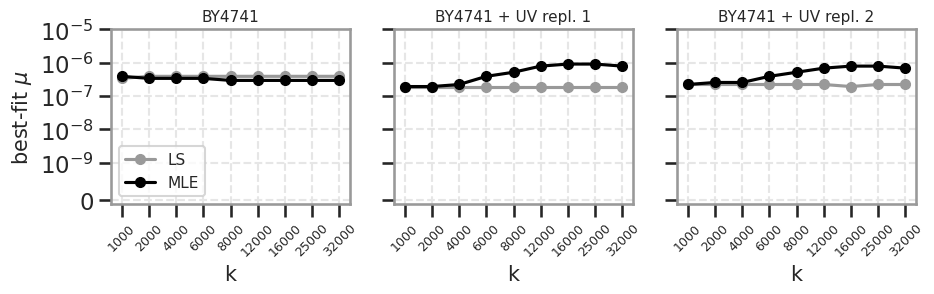

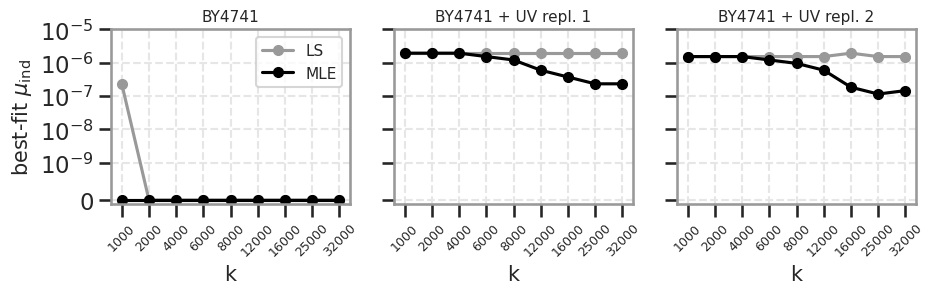

In [6]:
xpos = np.arange(len(kvals))
for fname, col, lab in (("figS06e_bestFitMu_vs_k.svg", "mu_best", r"best-fit $\mu$"),
                        ("figS06f_bestFitMuInd_vs_k.svg", "mu_ind_best",
                         r"best-fit $\mu_{\mathrm{ind}}$")):
    fig, axs = plt.subplots(1, 3, figsize=(3 / 4 * 0.8 * 16, 0.8 * 4), sharey=True)
    for ax, key in zip(axs, expt3.KEYS):
        for tbl, colour, label in ((ls_tbl, '0.6', "LS"),
                                   (mle_tbl, colorTable['k'], "MLE")):
            rows = tbl.loc[tbl.key == key].set_index("k").loc[kvals]
            ax.plot(xpos, rows[col].values, "-o", color=colour, markersize=7, label=label)
        ax.set_xticks(xpos)
        ax.set_xticklabels([str(k) for k in kvals], rotation=45, fontsize=9)
        ax.set_xlabel("k")
        ax.set_title(expt3.KEY_LABELS[key], fontsize=11)
    axs[0].set_yscale("symlog", linthresh=1e-9)
    axs[0].set_ylim(-1e-10, 1e-5)
    axs[0].set_ylabel(lab)
    axs[0].legend(fontsize=11)
    plt.tight_layout(); plt.savefig(OUT / fname, bbox_inches="tight", dpi=300); plt.show()

## rebuild the likelihood and loss surfaces at k = 4000

In [7]:
log_likelihood_by_key, loss_by_key = {}, {}
for key in expt3.KEYS:
    log_likelihood_by_key[key] = log_likelihood_surface(blocks[(key, K_PLOT)], alpha)
    loss_by_key[key] = ccdf_loss_surface(blocks[(key, K_PLOT)], alpha)
    log_likelihood, loss = log_likelihood_by_key[key], loss_by_key[key]
    i_mu, i_mu_ind = np.unravel_index(np.argmax(log_likelihood), log_likelihood.shape)
    j_mu, j_mu_ind = np.unravel_index(
        np.nanargmin(np.where(np.isfinite(loss), loss, np.nan)), loss.shape)
    print(f"{key}  (alpha = {alpha:.3f})")
    spontaneous_only = int(np.argmax(log_likelihood[:, 0]))
    print(f"   MLE: mu = {expt3.MU_GRID[i_mu]:.3e}, "
          f"mu_ind = {expt3.MU_IND_GRID[i_mu_ind]:.3e}"
          f"   | spontaneous-only model: mu = {expt3.MU_GRID[spontaneous_only]:.3e}")
    print(f"   LS : mu = {expt3.MU_GRID[j_mu]:.3e}, "
          f"mu_ind = {expt3.MU_IND_GRID[j_mu_ind]:.3e}")

20260224_yKH88  (alpha = 3.425)
   MLE: mu = 3.393e-07, mu_ind = 0.000e+00   | spontaneous-only model: mu = 3.393e-07
   LS : mu = 3.907e-07, mu_ind = 0.000e+00
20260224_yKH88UV_A  (alpha = 3.425)
   MLE: mu = 2.223e-07, mu_ind = 1.931e-06   | spontaneous-only model: mu = 9.103e-07
   LS : mu = 1.931e-07, mu_ind = 1.931e-06
20260224_yKH88UV_B  (alpha = 3.425)
   MLE: mu = 2.560e-07, mu_ind = 1.526e-06   | spontaneous-only model: mu = 9.103e-07
   LS : mu = 2.223e-07, mu_ind = 1.526e-06


## S6a, S6b: delta NLL

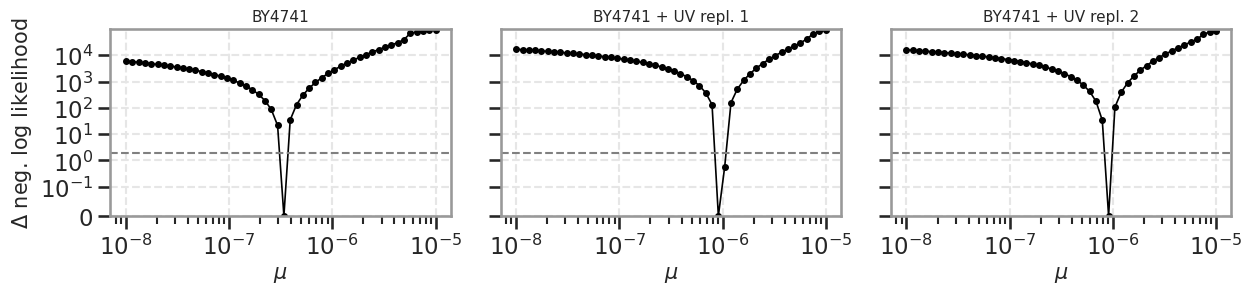

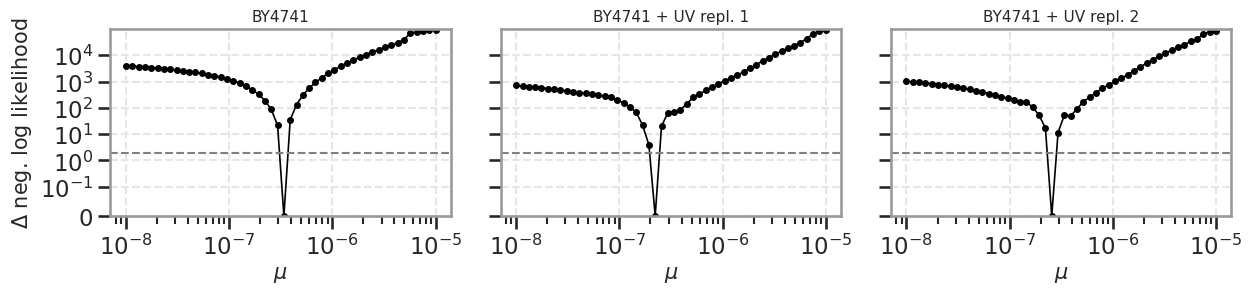

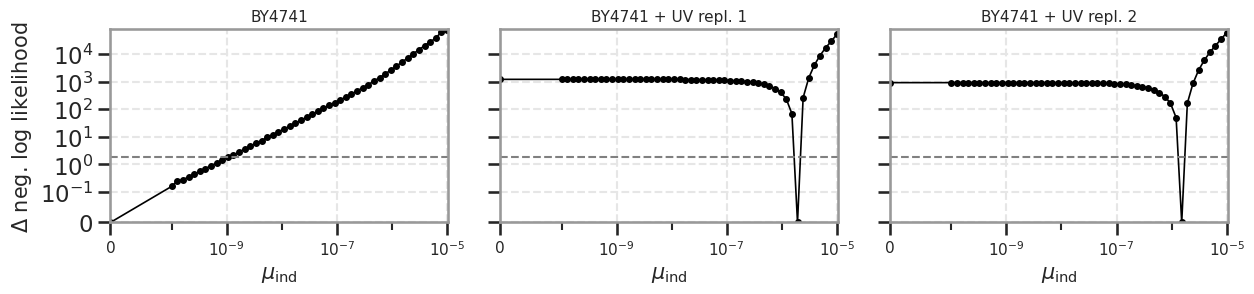

In [8]:
def dnll_panel(values, xgrid, fname, xlabel, symlog_x=False):
    fig, axs = plt.subplots(1, 3, figsize=(0.8 * 16, 0.8 * 4), sharey=True)
    for ax, key in zip(axs, expt3.KEYS):
        neg_log_likelihood = values(key)
        ax.plot(xgrid, neg_log_likelihood - np.min(neg_log_likelihood), "-o", color=colorTable['k'],
                markersize=4, linewidth=1.2)
        ax.axhline(WILKS_95, color='gray', linestyle='--', linewidth=1.5)
        if symlog_x:
            ax.set_xscale("symlog", linthresh=1e-10)
            ax.set_xlim(left=0)
            ax.set_xticks([0, 1e-9, 1e-7, 1e-5])
            ax.set_xticklabels(['0', r'$10^{-9}$', r'$10^{-7}$', r'$10^{-5}$'], fontsize=11)
        else:
            ax.set_xscale("log")
        ax.set_xlabel(xlabel)
        ax.set_title(expt3.KEY_LABELS[key], fontsize=11)
    axs[0].set_yscale("symlog", linthresh=0.1)
    axs[0].set_ylim(bottom=0)
    axs[0].set_ylabel(r"$\Delta$ neg. log likelihood")
    plt.tight_layout(); plt.savefig(OUT / fname, bbox_inches="tight", dpi=300); plt.show()

dnll_panel(lambda k: -log_likelihood_by_key[k][:, 0], expt3.MU_GRID,
           "figS06a_dNLL_muOnly.svg", r"$\mu$")
dnll_panel(lambda k: np.min(-log_likelihood_by_key[k], axis=1), expt3.MU_GRID,
           "figS06b_dNLL_muCombined.svg", r"$\mu$")
dnll_panel(lambda k: np.min(-log_likelihood_by_key[k], axis=0), expt3.MU_IND_GRID,
           "figS06b_dNLL_muInd.svg", r"$\mu_{\mathrm{ind}}$", symlog_x=True)

## S6c, S6d: least-squares CCDF overlays

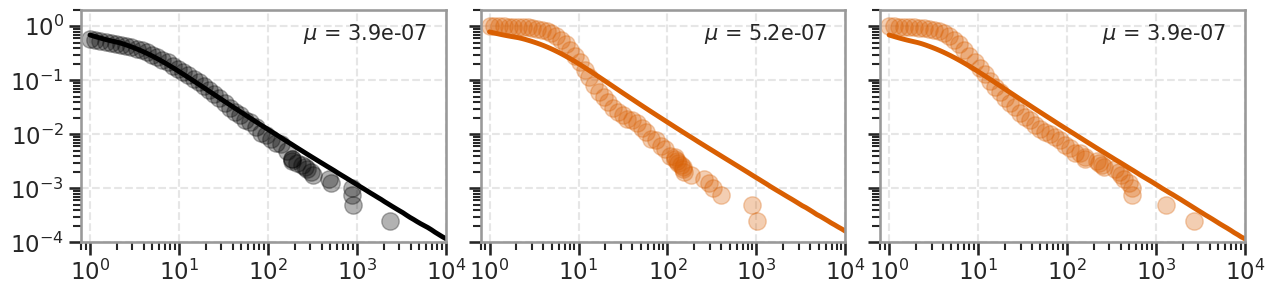

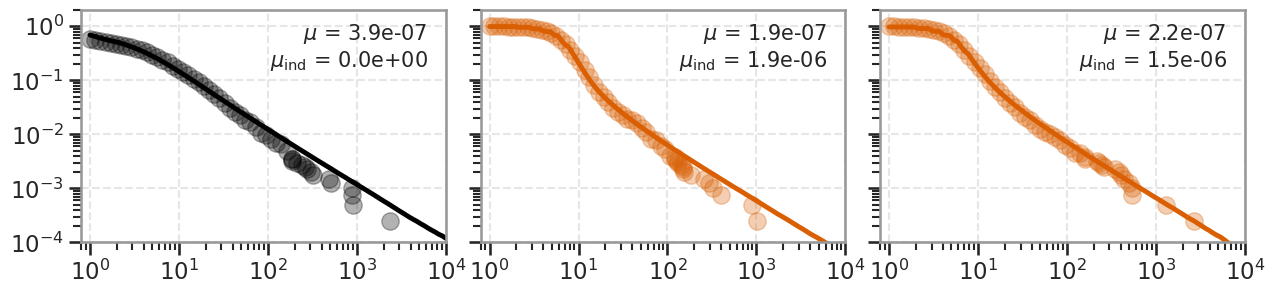

Done in 9s.


In [9]:
plot_ccdf_overlay(blocks, ls_tbl, K_PLOT,
                     OUT / "figS06c_bestfitCCDF_muind0_LS.svg", model="spontaneous")
plot_ccdf_overlay(blocks, ls_tbl, K_PLOT,
                     OUT / "figS06d_bestfitCCDF_LS.svg", model="combined")

print(f"Done in {time.time()-t_start:.0f}s.")